# Nivell 1 · Com s'usen avui els espais de l'Escola, i hi cap el model nou?

**Repte d'horaris i espais 2027-28 · UAB THE HACK! 2026**

Aquest quadern respon la pregunta del nivell 1 amb les dades del paquet (`paquet/sessions.csv`, `aules.csv`).
Es pot tornar a executar de dalt a baix (Cell → Run All) des de la carpeta `repte-horaris-escola`.

**Com llegir-lo:** cada troballa té la xifra, el gràfic i el càlcul. Al final hi ha el resum de les cinc troballes.

**Definicions que fem servir (les mateixes que el verificador):**
- *Semestre* = per data (setembre-gener = 1r, febrer-juny = 2n).
- *Classe* = una sessió; si una sessió és compartida entre titulacions (`id_compartida`) compta una sola vegada.
- *Aula ordinària* = «Aules docents» (21). Al matí en comptem 19: les 21 menys 2 que s'han de deixar lliures.
- Analitzem el **2n semestre** (el que avui està més per fer).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

DATA = Path('paquet')
s = pd.read_csv(DATA/'sessions.csv', dtype={'codi': str}, keep_default_na=False)
aules = pd.read_csv(DATA/'aules.csv')

hm = lambda x: int(x[:2])*60 + int(x[3:])
s['data'] = pd.to_datetime(s['data'])
s['semestre_n'] = s['data'].apply(lambda d: 1 if d.month >= 9 or d.month == 1 else 2)
s['ini'], s['fi'] = s.h_ini.map(hm), s.h_fi.map(hm)
s['unitat'] = np.where(s.id_compartida != '', s.id_compartida, s.id_sessio)   # classe física (compartida = 1)
s['al_mati'] = s.ini < 14*60 + 30                                             # el torn el marca l'hora d'inici
s['torn_ok'] = s.al_mati == (s.torn_requerit == 'mati')
s['hores'] = s.durada_min / 60
s2 = s[s['semestre_n'] == 2].copy()
cap = aules.set_index('aula').capacitat.to_dict()
explota = lambda df: df.assign(coh=df.titulacions_curs.str.split('|')).explode('coh')

print(f"{len(s):,} sessions · 1r semestre {int((s.semestre_n==1).sum()):,} · 2n semestre {len(s2):,}")
print(aules.groupby('tipus').capacitat.agg(['count', 'min', 'max']))


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 739, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



ImportError: numpy.core.multiarray failed to import

## Troballa 1 · El 42 % de les classes del 2n semestre són avui al torn que no els toca

El model nou vol 1r i 2n al matí i la resta a la tarda. Comparem l'hora d'inici real de cada classe amb el torn que li toca (`torn_requerit`).

Sessions del 2n semestre                                                                                            7739
Fora del seu torn (total)                                                                                           3246
   de les quals fixades (laboratoris i GEI/GEET 1r-2n): no es poden moure, el verificador les dona per heretades    1238
   de les quals mobles: són les que compten (R1-TORN)                                                               2008

% fora de torn: 41.9 %


,sessions,fora_de_torn,%
coh,,,
GEI:3r,1381,1232,89.2
GEI:4t,1217,1125,92.4
GEST:3r,527,521,98.9
GEI:2n,1168,406,34.8
GEI:1r,998,328,32.9
GEET:3r,238,232,97.5
GEQ:3r,163,163,100.0
GCIS:2n,124,124,100.0
GEST:4t,112,112,100.0


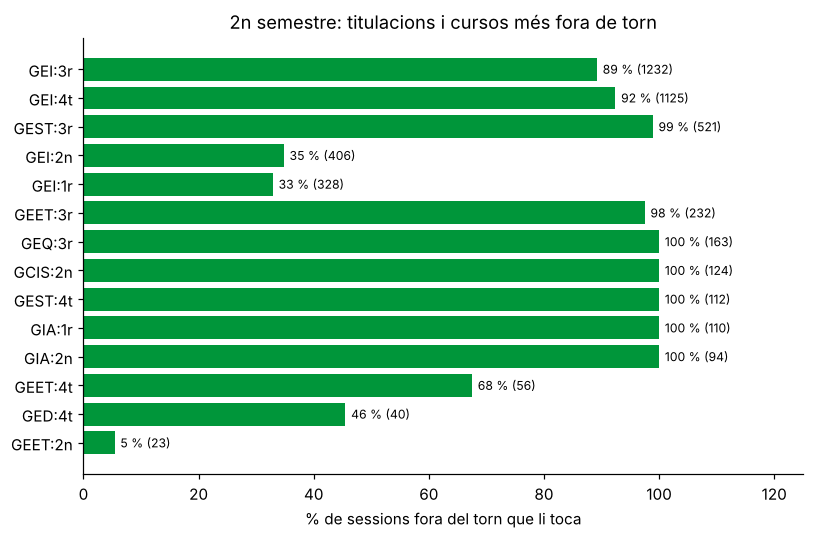

In [ ]:
fora = s2[~s2.torn_ok]
resum = pd.Series({
    'Sessions del 2n semestre': len(s2),
    'Fora del seu torn (total)': len(fora),
    '   de les quals fixades (laboratoris i GEI/GEET 1r-2n): no es poden moure, el verificador les dona per heretades': int((fora.fixada != '').sum()),
    '   de les quals mobles: són les que compten (R1-TORN)': int((fora.fixada == '').sum()),
})
print(resum.to_string())
print(f"\n% fora de torn: {100*len(fora)/len(s2):.1f} %")

t = explota(s2).groupby('coh').size().rename('sessions').to_frame()
t['fora_de_torn'] = explota(fora).groupby('coh').size()
t = t.fillna(0).astype(int)
t['%'] = (100*t.fora_de_torn/t.sessions).round(1)
t = t.sort_values('fora_de_torn', ascending=False)
display(t.head(16))

top = t.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(top.index, top['%'], color='#00963a')
for i, (p, n) in enumerate(zip(top['%'], top.fora_de_torn)):
    ax.text(p + 1, i, f'{p:.0f} % ({n})', va='center', fontsize=8)
ax.set_xlim(0, 125); ax.set_xlabel('% de sessions fora del torn que li toca')
ax.set_title('2n semestre: titulacions i cursos més fora de torn')
plt.tight_layout(); plt.show()

**Lectura:** el canvi gros és sobretot de **3r i 4t de GEI**, que avui fan classe majoritàriament al matí i haurien de passar a la tarda.
També passen del tot a la tarda GEST 3r, GEET 3r, GEQ 3r i GEST 4t, i al matí GCIS 2n, GIA 1r i GIA 2n (el 100 % de les seves sessions són avui al torn contrari).

## Troballa 2 · Hi cap el matí: sí, i amb marge, perquè gairebé tot el que s'ha de moure surt del matí i no hi entra

Comparem les hores-aula que demana el matí amb les que ofereix: 19 aules × 6 h × dies de classe de la setmana. Es compten classes de teoria, problemes i seminaris (sense laboratoris PLAB ni dobles titulacions, que no ocupen aula ordinària).

Tres escenaris:
- **Avui**: les classes que ja són al matí i que hi toquen.
- **Model nou, tot mòbil**: totes les que han de ser al matí (és la referència de l'enunciat, 67-70 %).
- **Model nou realista**: les classes fixades (GEI/GEET 1r-2n) que avui ja són a la tarda *no es poden moure*, així que no entren al matí.

,avui,model_nou_tot_mobil,model_nou_realista
setmana,,,
2027-W05,52.8,68.2,57.2
2027-W06,54.2,69.6,58.6
2027-W07,54.0,69.5,58.4
2027-W08,53.0,68.4,57.4
2027-W09,53.7,69.1,58.1
2027-W10,54.0,69.5,58.4
2027-W11,48.7,64.9,53.5
2027-W13,7.0,7.0,7.0
2027-W14,12.6,15.4,12.8


Mediana % ocupació del matí: {'avui': 52.1, 'model_nou_tot_mobil': 67.6, 'model_nou_realista': 56.5}


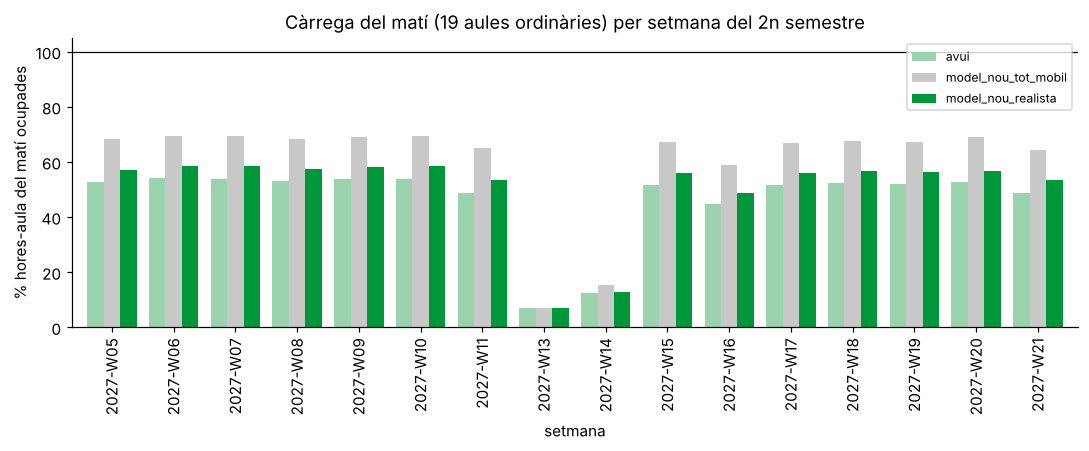

In [ ]:
u = s2[(s2.sense_espai != '1') & (s2.tipus != 'PLAB')].drop_duplicates('unitat').copy()
dies = s2.groupby('setmana').data.nunique()                  # dies amb classe aquella setmana
w = pd.DataFrame({'dies_amb_classe': dies})
mati = u[u.torn_requerit == 'mati']
w['avui'] = mati[mati.al_mati].groupby('setmana').hores.sum()
w['model_nou_tot_mobil'] = mati.groupby('setmana').hores.sum()
real = u[((u.fixada != '') & u.al_mati) | ((u.fixada == '') & (u.torn_requerit == 'mati'))]
w['model_nou_realista'] = real.groupby('setmana').hores.sum()
w = w.fillna(0)
oferta = 19 * 6 * w.dies_amb_classe
pct = pd.DataFrame({k: (100*w[k]/oferta).round(1) for k in ['avui', 'model_nou_tot_mobil', 'model_nou_realista']})
pct = pct[w.dies_amb_classe >= 4]                              # setmanes lectives completes
display(pct)
print('Mediana % ocupació del matí:', pct.median().round(1).to_dict())

ax = pct.plot(kind='bar', figsize=(10, 4.2), color=['#9bd3ae', '#c8c8c8', '#00963a'], width=.8)
ax.axhline(100, color='k', lw=.8); ax.set_ylim(0, 105); ax.set_ylabel('% hores-aula del matí ocupades')
ax.set_title('Càrrega del matí (19 aules ordinàries) per setmana del 2n semestre'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Pic de classes alhora al matí avui (classes que li toquen al matí) i quantes n'han de pujar / baixar
def pic(df, lo=8*60+30, hi=14*60+30):
    m = 0
    for _, g in df.groupby('data'):
        for t0 in range(lo, hi, 30):
            m = max(m, int(((g.ini < t0+30) & (g.fi > t0)).sum()))
    return m
print('Pic de classes alhora al matí avui (les que li toquen al matí):', pic(mati[mati.al_mati]), 'de 19 aules')
print('Pic avui al matí comptant TOTES les classes (també les de tarda que avui hi són):', pic(u[u.al_mati]))

wk = u[u.setmana == '2027-W06']                               # setmana tipus
mob = wk[wk.fixada == '']; fix = wk[wk.fixada != '']
print('\nSetmana tipus 2027-W06 (hores per setmana):')
print('  Mòbils que han de PUJAR al matí      :', mob[(mob.torn_requerit=='mati') & ~mob.al_mati].hores.sum(), 'h')
print('  Mòbils que han de BAIXAR a la tarda  :', mob[(mob.torn_requerit=='tarda') & mob.al_mati].hores.sum(), 'h')
print('  Fixades a la tarda que no es poden pujar:', fix[(fix.torn_requerit=='mati') & ~fix.al_mati].hores.sum(), 'h')
cohmati = explota(mob[(mob.torn_requerit=='mati') & ~mob.al_mati]).groupby('coh').hores.sum()
print('\nQui puja al matí (h/setmana):'); print(cohmati.to_string())
tarda = u[u.torn_requerit == 'tarda'].groupby('setmana').hores.sum()
print('\nTarda nova: ocupació mediana', round(float((100*tarda/(19*6.5*dies)).dropna()[dies>=4].median()), 1), '% de les 19 aules (6,5 h/dia)')

Pic de classes alhora al matí avui (les que li toquen al matí): 15 de 19 aules
Pic avui al matí comptant TOTES les classes (també les de tarda que avui hi són): 22

Setmana tipus 2027-W06 (hores per setmana):
  Mòbils que han de PUJAR al matí      : 25.0 h
  Mòbils que han de BAIXAR a la tarda  : 150.0 h
  Fixades a la tarda que no es poden pujar: 63.0 h

Qui puja al matí (h/setmana):
coh
GCIS:2n    14.0
GIA:1r      7.0
GIA:2n      4.0

Tarda nova: ocupació mediana 39.4 % de les 19 aules (6,5 h/dia)


**Lectura:** l'enunciat diu que el matí quedarà «just» (67-70 %). Això és el cas més pessimista, que suposa que tot es pot moure.
La realitat és més favorable: gairebé totes les classes que haurien de ser al matí **ja hi són** (o són fixades i no es poden moure). A la setmana tipus només **25 h/setmana** han de pujar al matí (GCIS 2n, GIA 1r i GIA 2n),
mentre que unes **150 h/setmana** de 3r/4t han de baixar a la tarda, que avui queda al voltant del 40 % d'ocupació.

## Troballa 3 · Hi ha aules lliures a cada franja del matí, i la mida no és el coll d'ampolla

Posem les classes fixades que ja són al matí (no es poden moure) i mirem quantes de les 19 aules queden lliures a cada franja de mitja hora. Després mirem si la demanda per mida d'aula és un problema.

,8:30,9:00,9:30,10:00,10:30,11:00,11:30,12:00,12:30,13:00,13:30,14:00
L,13,13,14,14,13,13,14,14,14,14,15,15
M,13,13,13,13,9,9,9,9,12,12,12,12
X,13,13,13,13,14,14,14,14,16,16,16,16
J,12,12,13,13,10,10,10,10,12,12,12,12
V,10,10,12,12,12,12,11,11,15,15,14,14


Aules lliures al matí amb només les fixades: mínim 9 · mitjana 12.7 de 19


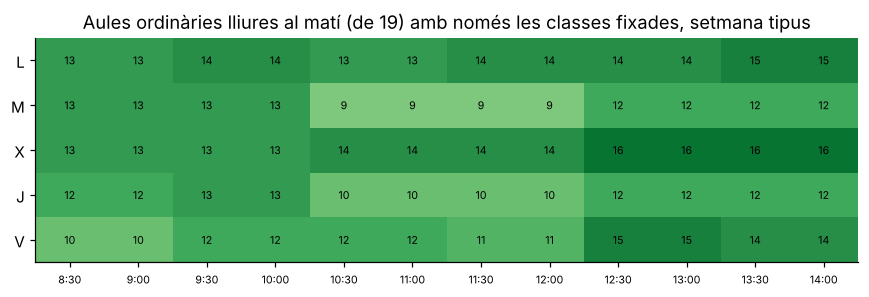

,cal ≥ places,demanda h/setm,oferta aules ordinàries h/setm,% demanda/oferta
0,0,397.0,630,63
1,49,167.0,510,33
2,64,96.0,420,23
3,89,41.0,360,11
4,101,22.0,150,15
5,118,2.0,90,2
6,131,0.0,30,0


Classes de matí amb més de 117 alumnes aquesta setmana: 1


In [ ]:
slots = list(range(8*60+30, 14*60+30, 30))
fixm = wk[(wk.fixada != '') & wk.al_mati]
lliures = pd.DataFrame({d: [19 - int(((g.ini < t+30) & (g.fi > t)).sum()) for t in slots]
                        for d, g in ((d, fixm[fixm.dia == d]) for d in 'LMXJV')},
                       index=[f'{t//60}:{t%60:02d}' for t in slots]).T
display(lliures)
print('Aules lliures al matí amb només les fixades: mínim', lliures.values.min(), '· mitjana', round(lliures.values.mean(), 1), 'de 19')

fig, ax = plt.subplots(figsize=(8, 2.8))
im = ax.imshow(lliures.values, cmap='Greens', vmin=0, vmax=19, aspect='auto')
ax.set_xticks(range(len(slots))); ax.set_xticklabels(lliures.columns, fontsize=7)
ax.set_yticks(range(5)); ax.set_yticklabels(list('LMXJV'))
for i in range(5):
    for j in range(len(slots)):
        ax.text(j, i, lliures.values[i, j], ha='center', va='center', fontsize=7)
ax.set_title('Aules ordinàries lliures al matí (de 19) amb només les classes fixades, setmana tipus')
plt.tight_layout(); plt.show()

# Per mida: demanda d'hores setmanals de les classes que van al matí vs oferta d'aules ordinàries de com a mínim aquesta mida
ordin = sorted(aules[aules.ordinaria == 1].capacitat)
mt = wk[wk.torn_requerit == 'mati']
filas = []
for k in (0, 49, 64, 89, 101, 118, 131):
    dem = mt[mt.alumnes >= k].hores.sum()
    ofe = sum(1 for c in ordin if c >= k) * 6 * 5
    filas.append({'cal ≥ places': k, 'demanda h/setm': dem, 'oferta aules ordinàries h/setm': ofe, '% demanda/oferta': round(100*dem/ofe)})
display(pd.DataFrame(filas))
print('Classes de matí amb més de 117 alumnes aquesta setmana:', int((mt.alumnes > 117).sum()))

**Lectura:** el mínim d'aules lliures és 9 de 19 (dimarts i dijous de 10.30 a 12.30) i la mitjana 12,7. A cap mida la demanda arriba a la meitat de l'oferta, de manera que les aules grans (130-160 places) no són un coll d'ampolla.

## Troballa 4 · El 74 % de les classes del 2n semestre no tenen aula a les dades, i les dades d'ocupació d'avui són incompletes

Això limita qualsevol conclusió sobre «quines aules van plenes»: només coneixem l'aula del 26 % de les classes.

Sessions 2n semestre                           7739
Sense aula                                     5722
   PLAB (no es toquen, ni l'aula)               919
   Dobles titulacions (no necessiten espai)     262
   Per assignar (R5-SENSE-AULA)                4541

Aules ordinàries sense cap classe assignada la setmana tipus: 7 de 21
['Q4/0003', 'Q3/1011', 'Q4/0007', 'Q3/1007', 'Q3/1003', 'Q3/0011', 'Q1/1011']


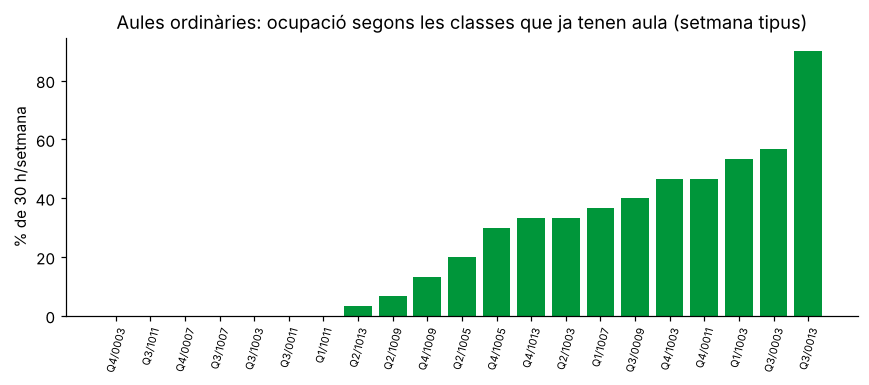


Per tipus d'espai (mitjana % ocupació):
tipus
Aules docents          24.0
Aules informàtiques    88.0
Laboratoris docents     5.0
Seminaris               2.0


In [ ]:
sa = s2.aula_partida == ''
print(pd.Series({
    'Sessions 2n semestre': len(s2),
    'Sense aula': int(sa.sum()),
    '   PLAB (no es toquen, ni l\'aula)': int((sa & (s2.tipus == 'PLAB')).sum()),
    '   Dobles titulacions (no necessiten espai)': int((sa & (s2.sense_espai == '1')).sum()),
    '   Per assignar (R5-SENSE-AULA)': int((sa & (s2.tipus != 'PLAB') & (s2.sense_espai != '1')).sum()),
}).to_string())

known = s2[s2.aula_partida.isin(cap)]
w6 = known[known.setmana == '2027-W06']
occ = (w6.groupby('aula_partida').hores.sum() / 30 * 100)                 # 30 h/setmana d'oferta
oc = aules.set_index('aula').join(occ.rename('ocupacio_pct')).fillna({'ocupacio_pct': 0})
ordi = oc[oc.ordinaria == 1].sort_values('ocupacio_pct')
print('\nAules ordinàries sense cap classe assignada la setmana tipus:', int((ordi.ocupacio_pct == 0).sum()), 'de', len(ordi))
print(list(ordi[ordi.ocupacio_pct == 0].index))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(ordi.index, ordi.ocupacio_pct, color='#00963a'); ax.tick_params(axis='x', rotation=75, labelsize=7)
ax.set_ylabel('% de 30 h/setmana'); ax.set_title('Aules ordinàries: ocupació segons les classes que ja tenen aula (setmana tipus)')
plt.tight_layout(); plt.show()
print('\nPer tipus d\'espai (mitjana % ocupació):'); print(oc.groupby('tipus').ocupacio_pct.mean().round(0).to_string())

**Lectura:** la majoria d'aules ordinàries semblen buides perquè les seves classes **encara no tenen aula assignada**, no perquè no s'usin. Q3/0013 (48 places) és la més carregada (90 %). Per això el 5.1 és el primer pas: sense aules assignades no es pot parlar d'ocupació real.

## Troballa 5 · 101 sessions del 2n semestre tenen més alumnes que places a l'aula on són avui

Es compara, per classe física, la suma d'alumnes amb la capacitat de l'aula actual.

In [ ]:
def sobreaforament(df):
    d = df[df.aula_partida.isin(cap) & (df.sense_espai != '1')]
    g = d.groupby(['unitat', 'aula_partida']).agg(alumnes=('alumnes', 'sum'), n_sessions=('id_sessio', 'count'),
                                                  fixada=('fixada', lambda x: (x != '').any()),
                                                  codi=('codi', 'first'), grup=('grup', 'first'),
                                                  cohort=('titulacions_curs', 'first')).reset_index()
    g['places'] = g.aula_partida.map(cap)
    g['excedent'] = g.alumnes - g.places
    return g[g.alumnes > g.places].sort_values('excedent', ascending=False)

ex2 = sobreaforament(s2)
print(f'2n semestre: {len(ex2)} classes amb més alumnes que places '
      f'({int(ex2.fixada.sum())} fixades: no es poden canviar; {int((~ex2.fixada).sum())} es poden corregir)')
display(ex2.head(8)[['codi', 'grup', 'cohort', 'aula_partida', 'alumnes', 'places', 'excedent', 'fixada']])
print('Excedent mitjà:', round(ex2.excedent.mean(), 1), 'alumnes · màxim:', int(ex2.excedent.max()))
print('1r semestre (per comparar):', len(sobreaforament(s[s.semestre_n == 1])), 'classes')

2n semestre: 101 classes amb més alumnes que places (58 fixades: no es poden canviar; 43 es poden corregir)


,codi,grup,cohort,aula_partida,alumnes,places,excedent,fixada
1159,106043,TE/21,GEQ:1r,Q4/0011,125,117,8,False
1158,106043,TE/21,GEQ:1r,Q4/0011,125,117,8,False
1157,106043,TE/21,GEQ:1r,Q4/0011,125,117,8,False
1156,106043,TE/21,GEQ:1r,Q4/0011,125,117,8,False
1155,106043,TE/21,GEQ:1r,Q4/0011,125,117,8,False
1179,106043,TE/21,GEQ:1r,Q4/0011,125,117,8,False
1180,106043,TE/21,GEQ:1r,Q4/0011,125,117,8,False
1181,106043,TE/21,GEQ:1r,Q4/0011,125,117,8,False


Excedent mitjà: 3.7 alumnes · màxim: 8


1r semestre (per comparar): 473 classes


## Resum: les cinc troballes

| # | Troballa | Xifra | Com s'ha calculat |
|---|---|---|---|
| 1 | Moltes classes són al torn que no els toca | **3.246 de 7.739 sessions (42 %)** fora de torn al 2n semestre; 2.008 mobles. GEI 3r i 4t: 89 % i 92 % | hora d'inici abans de les 14.30 = matí; comparat amb `torn_requerit` |
| 2 | El matí hi cap | Ocupació del matí **~56 %** (realista) fins a **67-70 %** (tot mòbil), amb 19 aules. Només 25 h/setm han de pujar al matí; 150 h/setm baixen a la tarda | hores-aula demanades / (19 aules × 6 h × dies de classe), classes compartides comptades un cop |
| 3 | No hi ha cap coll d'ampolla de franja ni de mida | Mínim 9 i mitjana 12,7 aules lliures de 19 al matí (només comptant les fixades); a cap mida la demanda passa de la meitat de l'oferta | concurrència per franja de 30 min; demanda vs oferta per mida d'aula |
| 4 | Les dades d'ús actual són incompletes | **74 % de les sessions** (5.722 de 7.739) sense aula: 4.541 per assignar, 919 PLAB, 262 dobles | `aula_partida` buida |
| 5 | Grups que no caben on són | **101 classes** amb més alumnes que places (58 fixades, 43 corregibles); p. ex. TE/21 GEQ 1r amb 125 alumnes a Q4/0011 (117) | suma d'`alumnes` per classe física vs `capacitat` |

**Conclusió per a l'Escola:** el model «1r i 2n al matí, la resta a la tarda» **cap a les aules** amb les dades actuals, amb marge al matí. L'esforç és sobretot moure unes 150 h/setmana de 3r i 4t (sobretot GEI) a la tarda. Les excepcions que no es poden evitar són les classes fixades de GEI i GEET+GEST (63 h/setmana a la tarda), que continuen fora del seu torn.

### Limitacions (important dir-ho al jurat)
- Ocupació per aula: només coneixem l'aula del 26 % de les sessions, així que les xifres d'ocupació són una cota baixa.
- Els alumnes de PAUL/PLAB/SEM són estimats pel repartiment de la teoria (`alumnes_origen`); 636 sessions no tenen dada.
- El càlcul de càrrega és agregat: confirma que hi cap en hores-aula; que hi càpiga *sense solapaments de professorat i alumnat* és el que resol el 5.2.
- No hem usat `validacio/` (ocupació real d'una setmana d'octubre); és el següent pas per contrastar el model.